# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

**Question.** A taxi (matatu) association runs 14-seater vehicles on three routes out of Kampala (Ntinda, Entebbe, Mukono). It wants to understand fares, forecast demand and decide how many vehicles to deploy.

**Approach.** Model routes and the fare market with classes, build a `Forecaster` hierarchy (moving average, exponential smoothing, linear trend), evaluate with rolling-origin backtesting, forecast day 11 and turn the forecast into a fleet size. The extension shows why a seasonal forecaster wins when demand has a weekly cycle.

**Reusable code** lives in `src/taxi_model.py` (`Route`, `MarketEquilibrium`, `Forecaster` and subclasses, `rolling_origin_backtest`, `tune_alpha`, `vehicles_needed`). Tests are in `tests/test_project5.py`.

**Data.** Ntinda counts come from the original question; the other routes are illustrative. Only 10 days of data exist, so every conclusion is tentative.

**Units.** Passengers per day; fares and revenue in UGX.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.taxi_model import (
    ExponentialSmoothing, LinearTrend, MarketEquilibrium, MovingAverage, Route,
    SeasonalNaive, rolling_origin_backtest, simulate_weekly_demand, tune_alpha, vehicles_needed,
)

SEED = 2026
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:,.2f}".format

## Task 1. `Route`: revenue and descriptive statistics

In [2]:
routes = [
    Route("Kampala-Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2_000),
    Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5_000),
    Route("Kampala-Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3_000),
]
rows = {}
for r in routes:
    d = r.describe()
    rows[r.name] = {
        "fare (UGX)": r.fare,
        "mean passengers/day": d["mean"],
        "variance": d["variance"],
        "std dev": d["std"],
        "total revenue (UGX)": r.total_revenue(),
        "mean daily revenue (UGX)": r.daily_revenue().mean(),
    }
display(pd.DataFrame(rows).T)
print(routes)

,fare (UGX),mean passengers/day,variance,std dev,total revenue (UGX),mean daily revenue (UGX)
Kampala-Ntinda,"2,000.00",47.40,54.27,7.37,"948,000.00","94,800.00"
Kampala-Entebbe,"5,000.00",67.80,45.07,6.71,"3,390,000.00","339,000.00"
Kampala-Mukono,"3,000.00",52.00,26.44,5.14,"1,560,000.00","156,000.00"


[Route('Kampala-Ntinda', 10 days, fare UGX 2,000), Route('Kampala-Entebbe', 10 days, fare UGX 5,000), Route('Kampala-Mukono', 10 days, fare UGX 3,000)]


Entebbe earns the most per day despite similar passenger counts to Mukono because its fare is higher. Ntinda carries the fewest passengers at the lowest fare, so it earns the least. Ntinda's passenger variance is the largest (54.3 passengers²), but variance is in squared units; compare routes with the standard deviation or relative to the mean.

## Task 2. Supply-demand equilibrium for Ntinda

Demand $Q_d = 120 - 0.02P$ and supply $Q_s = 10 + 0.03P$ ($P$ in UGX, $Q$ in passengers per trip-hour). Setting $Q_d = Q_s = Q$ gives a 2×2 linear system in $(Q, P)$:

$$\begin{pmatrix}1 & 0.02\\ 1 & -0.03\end{pmatrix}\begin{pmatrix}Q\\P\end{pmatrix}=\begin{pmatrix}120\\10\end{pmatrix}$$

Coefficient matrix:
 [[ 1.    0.02]
 [ 1.   -0.03]] 
Right-hand side: [120  10]

Equilibrium: P* = UGX 2,200, Q* = 76 passengers per trip-hour

At the current fare of UGX 2,000:
  demand  = 80,  supply = 70
  excess demand = +10 passengers per trip-hour (positive = shortage)


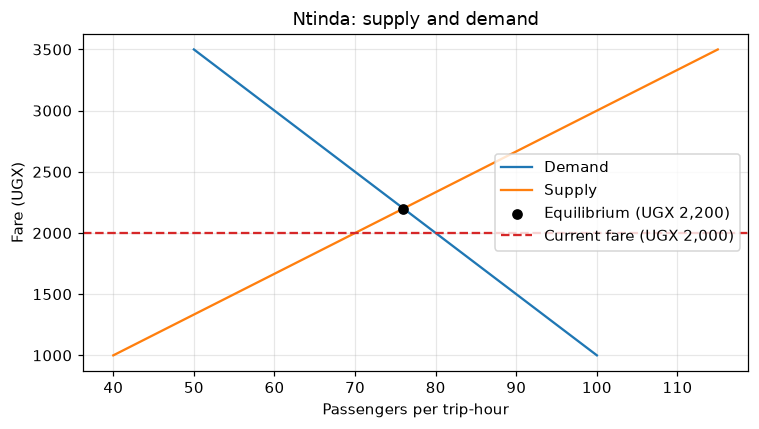

In [3]:
market = MarketEquilibrium(a_d=120, b_d=0.02, a_s=10, b_s=0.03)
print("Coefficient matrix:\n", market.matrix, "\nRight-hand side:", market.rhs)

q_star, p_star = market.solve()                       # scipy.linalg.solve
print(f"\nEquilibrium: P* = UGX {p_star:,.0f}, Q* = {q_star:.0f} passengers per trip-hour")
# Hand check: 120 - 0.02P = 10 + 0.03P  ->  P = 110/0.05 = 2,200;  Q = 120 - 0.02*2200 = 76
assert np.isclose(p_star, 2200) and np.isclose(q_star, 76)

fare = 2_000
print(f"\nAt the current fare of UGX {fare:,}:")
print(f"  demand  = {market.demand(fare):.0f},  supply = {market.supply(fare):.0f}")
print(f"  excess demand = {market.excess_demand(fare):+.0f} passengers per trip-hour (positive = shortage)")

p = np.linspace(1_000, 3_500, 100)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([market.demand(x) for x in p], p, label="Demand")
ax.plot([market.supply(x) for x in p], p, label="Supply")
ax.scatter([q_star], [p_star], c="k", zorder=3, label=f"Equilibrium (UGX {p_star:,.0f})")
ax.axhline(fare, ls="--", c="C3", label=f"Current fare (UGX {fare:,})")
ax.set(title="Ntinda: supply and demand", xlabel="Passengers per trip-hour", ylabel="Fare (UGX)")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.** The equilibrium fare is UGX 2,200 with 76 passengers per trip-hour. The current fare of UGX 2,000 is **below** equilibrium: at that fare 80 passengers per trip-hour want a seat but operators supply only 70, a shortage of 10. Expect queues and full vehicles, and pressure to raise the fare or add capacity. A small fare rise toward 2,200 would remove the shortage. Caveats: the demand and supply lines are assumed, not estimated from the 10-day data, and the equilibrium is in passengers per trip-hour, not the daily counts used elsewhere. The association may also cap fares for political or affordability reasons.

## Task 3. The `Forecaster` hierarchy

`Forecaster` is an abstract base class with `fit(history)` and `predict(horizon)`. Subclasses implement only `_predict` (and optionally `_fit`), so validation and the non-negative clipping live in one place:

| Class | Forecast |
|---|---|
| `MovingAverage(window=3)` | mean of the last 3 days (the original method) |
| `ExponentialSmoothing(alpha)` | level updated as $\ell_t=\alpha y_t+(1-\alpha)\ell_{t-1}$, flat forecast |
| `LinearTrend` | least-squares line (`np.polyfit`) extrapolated |
| `SeasonalNaive(period)` | value one season earlier (used in the extension) |

In [4]:
demo = routes[0].passengers
for m in [MovingAverage(3), ExponentialSmoothing(0.5), LinearTrend(), SeasonalNaive(7)]:
    print(f"{m.name:28s} next-day forecast for Ntinda: {m.fit(demo).predict(1)[0]:.1f}")

3-day moving average         next-day forecast for Ntinda: 48.0
SES (alpha=0.5)              next-day forecast for Ntinda: 47.2
linear trend                 next-day forecast for Ntinda: 53.7
seasonal naive (period 7)    next-day forecast for Ntinda: 50.0


## Task 4. Rolling-origin backtest (days 4-10) and tuning $\alpha$

For each target day $t$ from 4 to 10, every model is fitted on days $1..t-1$ only and predicts day $t$, so no future information leaks in. MAE is reported in passengers; revenue MAE is passengers × fare. Because the fare is constant per route, both rank models identically.

$\alpha$ is tuned by grid search over 0.1, 0.2, ..., 1.0, choosing the value with the smallest backtest MAE.

In [5]:
FIRST_TARGET = 4
alpha_tables, best_alpha = {}, {}
for r in routes:
    best, maes = tune_alpha(r.passengers, FIRST_TARGET)
    best_alpha[r.name], alpha_tables[r.name] = best, maes

print("Backtest MAE (passengers) by alpha:")
display(pd.DataFrame(alpha_tables).T)
print("Best alpha per route:", best_alpha)

def models_for(route):
    return [MovingAverage(3), ExponentialSmoothing(best_alpha[route.name]), LinearTrend()]

mae_pass, mae_rev = {}, {}
for r in routes:
    mae_pass[r.name] = {}
    for m in models_for(r):
        mae_pass[r.name][m.name.split(" (")[0] if m.name.startswith("SES") else m.name] = \
            rolling_origin_backtest(m, r.passengers, FIRST_TARGET)["mae"]
mae_pass = pd.DataFrame(mae_pass).T
mae_rev = mae_pass.mul([r.fare for r in routes], axis=0)
print("\nMAE in passengers per day:");  display(mae_pass)
print("MAE in revenue (UGX per day):"); display(mae_rev)
best_model_name = mae_pass.idxmin(axis=1)
print("Best model per route:"); display(best_model_name.to_frame("best model"))

Backtest MAE (passengers) by alpha:


,0.10,0.20,0.30,0.40,0.50,0.60,0.70,0.80,0.90,1.00
Kampala-Ntinda,10.60,7.94,7.35,7.06,6.72,6.40,6.15,5.97,5.88,5.86
Kampala-Entebbe,7.68,7.13,7.03,6.62,6.04,5.69,5.39,5.06,4.73,4.43
Kampala-Mukono,6.00,5.08,4.95,4.73,4.38,4.02,3.91,3.86,3.79,3.71


Best alpha per route: {'Kampala-Ntinda': 1.0, 'Kampala-Entebbe': 1.0, 'Kampala-Mukono': 1.0}

MAE in passengers per day:


,3-day moving average,SES,linear trend
Kampala-Ntinda,7.52,5.86,7.87
Kampala-Entebbe,7.19,4.43,7.71
Kampala-Mukono,5.33,3.71,6.39


MAE in revenue (UGX per day):


,3-day moving average,SES,linear trend
Kampala-Ntinda,"15,047.62","11,714.29","15,746.94"
Kampala-Entebbe,"35,952.38","22,142.86","38,556.69"
Kampala-Mukono,"16,000.00","11,142.86","19,171.77"


Best model per route:


,best model
Kampala-Ntinda,SES
Kampala-Entebbe,SES
Kampala-Mukono,SES


Simple exponential smoothing wins on every route, but the best $\alpha$ is **1.0**, the edge of the grid. At $\alpha = 1$ the forecast is just the last observed value (a "naïve" forecast), and the MAE falls steadily as $\alpha$ rises. So the tuning is really telling us that, on this short series, smoothing past days adds nothing and yesterday is the best predictor. The 3-day moving average lags because it averages in stale days, and the linear trend is hurt by the decline that follows the day-6 peak. With only 7 test points, and tuning and evaluating on the same points, the winning MAE is optimistic.

## Task 5. Day-11 revenue forecast

Each route is forecast with its best backtest model; the plot shows actual revenue, the one-step backtest forecasts and the day-11 forecast.

,model,passengers day 11,revenue day 11 (UGX)
Kampala-Ntinda,SES (alpha=1.0),45.00,"90,000.00"
Kampala-Entebbe,SES (alpha=1.0),64.00,"320,000.00"
Kampala-Mukono,SES (alpha=1.0),50.00,"150,000.00"


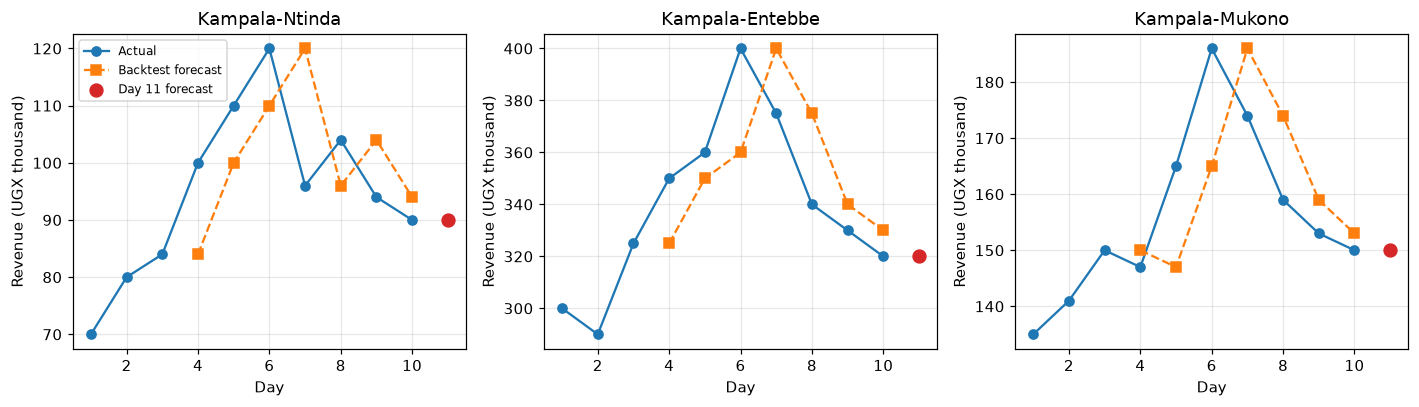

In [6]:
forecasts = {}
for r in routes:
    models = {m.name.split(" (")[0] if m.name.startswith("SES") else m.name: m for m in models_for(r)}
    model = models[best_model_name[r.name]]
    passengers_11 = float(model.fit(r.passengers).predict(1)[0])
    forecasts[r.name] = {"model": model.name, "passengers day 11": passengers_11,
                         "revenue day 11 (UGX)": passengers_11 * r.fare}
fc = pd.DataFrame(forecasts).T
display(fc)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, r in zip(axes, routes):
    model = {m.name.split(" (")[0] if m.name.startswith("SES") else m.name: m for m in models_for(r)}[best_model_name[r.name]]
    bt = rolling_origin_backtest(model, r.passengers, FIRST_TARGET)
    days = np.arange(1, len(r) + 1)
    ax.plot(days, r.daily_revenue() / 1e3, "o-", label="Actual")
    ax.plot(days[FIRST_TARGET - 1:], bt["pred"] * r.fare / 1e3, "s--", label="Backtest forecast")
    ax.scatter([11], [fc.loc[r.name, "revenue day 11 (UGX)"] / 1e3], c="C3", s=70, zorder=3, label="Day 11 forecast")
    ax.set(title=r.name, xlabel="Day", ylabel="Revenue (UGX thousand)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Task 6. Fleet planning for day 11

Each vehicle makes 8 one-way trips a day at 14 passengers, so it can carry at most 8 × 14 = **112 passengers per day**. Vehicles needed = ⌈forecast × 1.15 ÷ 112⌉: the 15% buffer is applied to demand before rounding **up** (rounding down would leave passengers stranded).

In [7]:
CAPACITY = 8 * 14
fleet = {}
for r in routes:
    f = fc.loc[r.name, "passengers day 11"]
    v = vehicles_needed(f, trips_per_day=8, seats=14, buffer=0.15)
    fleet[r.name] = {
        "forecast passengers": f,
        "with 15% buffer": f * 1.15,
        "vehicles": v,
        "utilisation of fleet (no buffer)": f / (v * CAPACITY),
        "highest observed day x 1.15": r.passengers.max() * 1.15,
    }
display(pd.DataFrame(fleet).T)
print(f"Capacity per vehicle = {CAPACITY} passengers/day. A second vehicle is only triggered above "
      f"{CAPACITY / 1.15:.1f} forecast passengers/day.")

,forecast passengers,with 15% buffer,vehicles,utilisation of fleet (no buffer),highest observed day x 1.15
Kampala-Ntinda,45.00,51.75,1.00,0.40,69.00
Kampala-Entebbe,64.00,73.60,1.00,0.57,92.00
Kampala-Mukono,50.00,57.50,1.00,0.45,71.30


Capacity per vehicle = 112 passengers/day. A second vehicle is only triggered above 97.4 forecast passengers/day.


**Reading the result.** One vehicle per route covers the forecast and even the busiest observed day with the buffer. Utilisation is only about 40-60%, so if the counts really are daily passengers per route, a single vehicle is enough and a second would sit half empty. This depends on the assumption that the given counts are total daily passengers per route and that all 8 trips run full-length; if the counts were per trip-hour or per direction, the fleet would be larger.

## Extension. Seasonal-naïve vs moving average on 60 simulated days

I simulate 60 days per route around each route's observed mean, with a weekly multiplier (Friday ×1.30, Sunday ×0.65) and 5% noise, using a fixed seed. Day 1 is a Monday. Backtests start on day 15 so every model has at least two weeks of history. A 7-day moving average is included as a fairer competitor to the 3-day one.

Backtest MAE (passengers/day), days 15-60:


,3-day moving average,7-day moving average,SES (alpha=0.1),linear trend,seasonal naive (period 7)
Kampala-Ntinda,8.11,6.22,6.22,6.33,2.46
Kampala-Entebbe,10.16,8.38,8.48,8.76,4.11
Kampala-Mukono,7.78,6.28,6.35,6.35,3.72


Winner per route: {'Kampala-Ntinda': 'seasonal naive (period 7)', 'Kampala-Entebbe': 'seasonal naive (period 7)', 'Kampala-Mukono': 'seasonal naive (period 7)'}


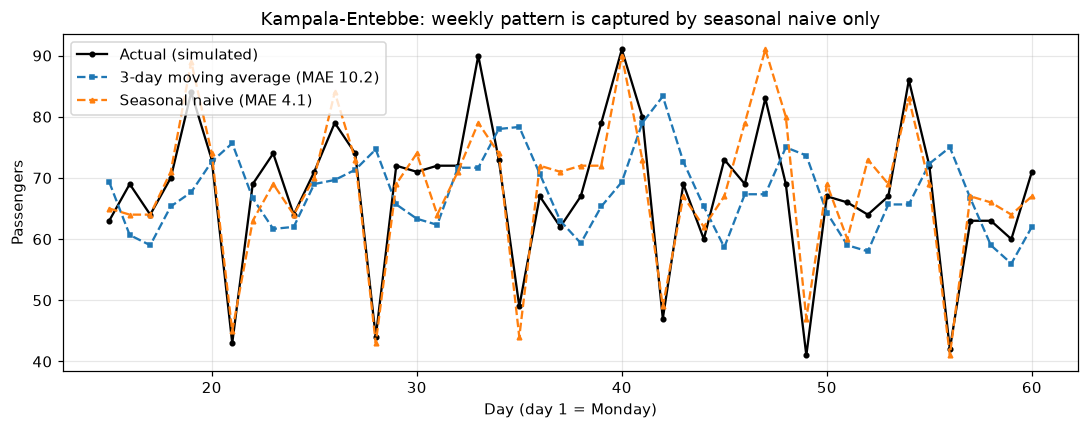

In [8]:
rng_seed = SEED
rows, sims = {}, {}
for k, r in enumerate(routes):
    y = simulate_weekly_demand(base=r.passengers.mean(), days=60, noise_cv=0.05, seed=rng_seed + k)
    sims[r.name] = y
    best_a, _ = tune_alpha(y, 15)
    models = [MovingAverage(3), MovingAverage(7), ExponentialSmoothing(best_a), LinearTrend(), SeasonalNaive(7)]
    rows[r.name] = {m.name: rolling_origin_backtest(m, y, 15)["mae"] for m in models}
ext = pd.DataFrame(rows).T
print("Backtest MAE (passengers/day), days 15-60:")
display(ext)
print("Winner per route:", ext.idxmin(axis=1).to_dict())

name = "Kampala-Entebbe"
y = sims[name]
sn = rolling_origin_backtest(SeasonalNaive(7), y, 15)
ma = rolling_origin_backtest(MovingAverage(3), y, 15)
days = np.arange(15, 61)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(days, sn["actual"], "o-", c="k", ms=3, label="Actual (simulated)")
ax.plot(days, ma["pred"], "s--", ms=3, label=f"3-day moving average (MAE {ma['mae']:.1f})")
ax.plot(days, sn["pred"], "^--", ms=3, label=f"Seasonal naive (MAE {sn['mae']:.1f})")
ax.set(title=f"{name}: weekly pattern is captured by seasonal naive only",
       xlabel="Day (day 1 = Monday)", ylabel="Passengers")
ax.legend(); plt.tight_layout(); plt.show()

The seasonal-naïve forecaster beats the 3-day moving average on all three routes (about 2.5-4 passengers/day of error against 8-10), and also beats the tuned exponential smoothing, the linear trend and the 7-day moving average. A moving average smooths over the weekly cycle, so it is always a few days late to the Friday peak and the Sunday dip; the seasonal forecaster simply repeats the same weekday from last week. The comparison is built on data I generated *with* a weekly pattern, so it demonstrates the mechanism rather than proving the real routes behave this way.

## Findings & Limitations

**Pricing.** The Ntinda fare of UGX 2,000 is below the UGX 2,200 equilibrium, leaving a shortage of 10 passengers per trip-hour (80 wanted, 70 supplied). That fits full vehicles and queues, and a modest fare rise would clear it.

**Forecasting.** Exponential smoothing beat the 3-day moving average and the linear trend on every route, but the grid search chose alpha = 1.0, which is simply "tomorrow equals today". Error fell steadily as alpha rose, so smoothing added nothing on this short, trending series. Backtest MAE was 3.7 to 5.9 passengers a day against 5.3 to 7.5 for the moving average. Day-11 forecasts are 45, 64 and 50 passengers, or UGX 90,000, 320,000 and 150,000 for Ntinda, Entebbe and Mukono.

**Fleet.** One vehicle per route covers the forecast and the busiest observed day with the 15% buffer; utilisation is 40-57%. A second vehicle is needed only above about 97 passengers a day.

**Extension.** On simulated data with a weekly cycle, seasonal naive cut MAE to 2.5-4.1 passengers against 7.8-10.2 for the 3-day average.

**Limitations.** Ten days of data give only seven backtest points, and alpha was tuned on those same points, so the MAEs are optimistic. The given days are not tied to weekdays, so weekly seasonality cannot be tested on them. Only the Ntinda counts are from the original question, and the supply and demand lines are assumed, not estimated. The fleet result assumes the counts are total daily passengers per route. Forecasts are single numbers with no intervals, and revenue is not profit. The extension data were generated with a weekly pattern, so its win shows the mechanism, not real behaviour.